# Extra experiment 1: rhythm features without the tempo

In the main experiment the rhythm models reach about 80% macro-F1 on the original audio, but they collapse when the music is played a bit faster or slower. The reason is that the cyclic tempogram we used still tells the model which tempo class a clip is in. So the main result says "our rhythm features mostly carry tempo", but not yet whether the rhythm pattern alone can tell the dances apart.

Here we remove the tempo from the rhythm features in two ways and run the same time-stretch test:

| Feature set | Inputs | What it is |
|---|---:|---|
| Rhythm (as before) | 19 | cyclic tempogram (15), bar ratios (3), PLP confidence (1), same as the main notebooks |
| Tempo only | 1 | `tau_hat`, same as the main notebooks |
| Rhythm, tempo removed | 19 | the same, but the cyclic tempogram is shifted so that its strongest bin is always bin 0 |
| Scale transform | 20 | a rhythm descriptor that does not change when the music is stretched (Holzapfel & Stylianou, 2011) |
| Rhythm, tempo removed + tempo | 20 | the tempo-free rhythm set plus `tau_hat`, to see what happens when we give the tempo back |

The first two sets are the ones from the main notebooks. We run them again here as a reference and to check that the pipeline gives the same numbers.

Both classifiers (Random Forest and SVM-RBF), the folds, the tuning and the 13 audio versions are the same as in the main project.

## 1. Imports

In [1]:
from pathlib import Path
import platform
import time
import warnings

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.metrics import f1_score

import features as F
import evaluation as E

# librosa 1.0 warns about arguments it passes to itself inside time_stretch; harmless, so hidden
warnings.filterwarnings('ignore', message='The `(hop_length|n_fft)` parameter is deprecated', category=FutureWarning)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180})
pd.set_option('display.max_columns', 30)
display(pd.Series({'python': platform.python_version(), 'numpy': np.__version__,
                   'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
                   'librosa': librosa.__version__}, name='version').to_frame())

,version
python,3.12.13
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
librosa,1.0.0


## 2. Settings

`DATASET_DIR` is the only path you may need to change. The features of all 13 versions are saved in `all_versions_features.csv` the first time and reused after that, also by the other notebook in this folder.

In [2]:
DATASET_DIR = Path('../BallroomData')                  # the folder with the dance folders
FEATURES_PATH = Path('all_versions_features.csv')       # shared by both notebooks in this folder
MAIN_RESULTS_DIR = Path('../results')                   # results of the main notebooks, only used for checks
RESULTS_DIR = Path('results') / 'rhythm_without_tempo'

EXPECTED_CLIPS = 698
N_JOBS = 8                          # CPU cores; set to 1 if parallel runs give problems
MODEL_NAMES = list(E.MODELS)        # Random Forest and SVM-RBF

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def save(table, name, **options):
    table.to_csv(RESULTS_DIR / name, **options)


def save_figure(figure, name):
    figure.savefig(RESULTS_DIR / name, bbox_inches='tight')
    plt.show()

## 3. Clips and folds

Same clips and same five test folds as the main notebooks: stratified by dance, and the 13 known duplicate pairs always stay in one fold. If the main results are there, we check that every clip is in the same fold as before, so the numbers can be compared directly.

In [3]:
clips = E.find_clips(DATASET_DIR)
class_labels = np.sort(clips['label'].unique())
assert len(clips) == EXPECTED_CLIPS and len(class_labels) == 8, f'found {len(clips)} clips in {DATASET_DIR}'

folds = E.make_folds(clips)
clips = clips.merge(folds[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')

main_folds = MAIN_RESULTS_DIR / 'rhythm_random_forest' / 'rhythm' / 'out_of_fold_predictions.csv'
if main_folds.is_file():
    before = pd.read_csv(main_folds).set_index('filename')['fold']
    assert (clips.set_index('filename')['fold'] == before.loc[clips['filename']]).all()
    print('every clip is in the same test fold as in the main notebooks')
display(pd.crosstab(clips['fold'], clips['label'], margins=True))

every clip is in the same test fold as in the main notebooks


label,ChaChaCha,Jive,Quickstep,Rumba,Samba,Tango,VienneseWaltz,Waltz,All
fold,,,,,,,,,
1,22,12,17,20,17,17,13,22,140
2,22,12,17,20,17,17,13,22,140
3,22,12,16,20,17,18,13,22,140
4,22,12,16,19,18,17,13,22,139
5,23,12,16,19,17,17,13,22,139
All,111,60,82,98,86,86,65,110,698


## 4. Features of all 13 versions

Every clip is used in 13 versions: the original, six stretches (−10%, −5%, −2%, +2%, +5%, +10%) and six round trips (stretched and stretched back, so the tempo is the original one again). The code is in `features.py`. The timbral and rhythm features there are the same code as in the main notebooks, and the shifted cyclic tempogram and the scale transform are new.

Computing everything takes about 15 minutes. If the run stops, starting the cell again continues where it stopped.

In [4]:
if F.is_complete(FEATURES_PATH, clips):
    print(f'using the saved features in {FEATURES_PATH}')
else:
    start = time.perf_counter()
    F.extract_all_versions(clips, DATASET_DIR, FEATURES_PATH, n_jobs=N_JOBS)
    print(f'computed in {(time.perf_counter() - start)/60:.1f} minutes')

versions = pd.read_csv(FEATURES_PATH)
feature_columns = F.TIMBRAL_COLUMNS + F.CYCLIC_COLUMNS + F.RATIO_COLUMNS + ['plp_confidence', 'tau_hat'] \
    + F.SHIFTED_COLUMNS + F.SCALE_COLUMNS
assert not versions.duplicated(['filename', 'condition']).any()
assert np.isfinite(versions[feature_columns].to_numpy(dtype=float)).all(), 'NaN or infinite values in the features'

# the training table: features of the original audio, with labels and folds
data = (versions[versions['condition'] == 'original']
        .merge(clips[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')
        .sort_values('filename').reset_index(drop=True))
print(f'{len(versions)} rows ({len(data)} clips x {len(F.CONDITIONS)} versions), {len(feature_columns)} feature columns')

using the saved features in all_versions_features.csv


9074 rows (698 clips x 13 versions), 85 feature columns


## 5. The two tempo-free rhythm features

**Shifted cyclic tempogram.** The cyclic tempogram folds all tempi into one octave, so 60, 120 and 240 BPM land in the same bin. But the bins are still tied to fixed tempo classes, so the position of the strongest bin tells the tempo class, and a 10% stretch moves the whole profile by about 2 of its 15 bins. If we rotate the profile so that the strongest bin is always bin 0, the shape stays (which other pulse levels are there, relative to the main one) but the tempo class is gone. This is the `shift=True` option that was already in `Rythm_extraction.py`.

**Scale transform.** We take the autocorrelation of the novelty curve, which shows after which time lags the music repeats itself (one beat, two beats, one bar and so on). When the music is played faster, this curve is squeezed along the lag axis, but its shape stays the same. If the lag axis is logarithmic, the squeeze turns into a shift, and the magnitude of a Fourier transform does not change when its input is shifted. The scale transform does exactly this: for an autocorrelation $r(t)$ it computes

$$S(c) = \int_0^\infty r(t)\, t^{-jc - \frac{1}{2}}\, dt$$

and with $t = e^u$ this becomes a normal Fourier transform of $r(e^u)\,e^{u/2}$. We use lags between 0.1 s and 4 s on a log axis with 256 points and keep the magnitude of the first 20 coefficients, normalised to length 1. This is the same idea as the tempo-insensitive representation of Jensen et al. (2009) from our proposal.

Before training anything, we check how much each representation changes when the audio is stretched. All three vectors have length 1, so the dot product between the original and the changed version is their cosine similarity: 1 means unchanged.

representation,Cyclic tempogram (as before),Scale transform,Shifted cyclic tempogram
condition,,,
stretch_0.90,0.865,0.989,0.991
stretch_0.95,0.925,0.988,0.997
stretch_0.98,0.983,0.989,0.984
stretch_1.02,0.982,0.988,0.983
stretch_1.05,0.926,0.986,0.998
stretch_1.10,0.873,0.984,0.997
roundtrip_0.90,0.998,0.980,0.998
roundtrip_0.95,0.998,0.979,0.998
roundtrip_0.98,0.998,0.978,0.998


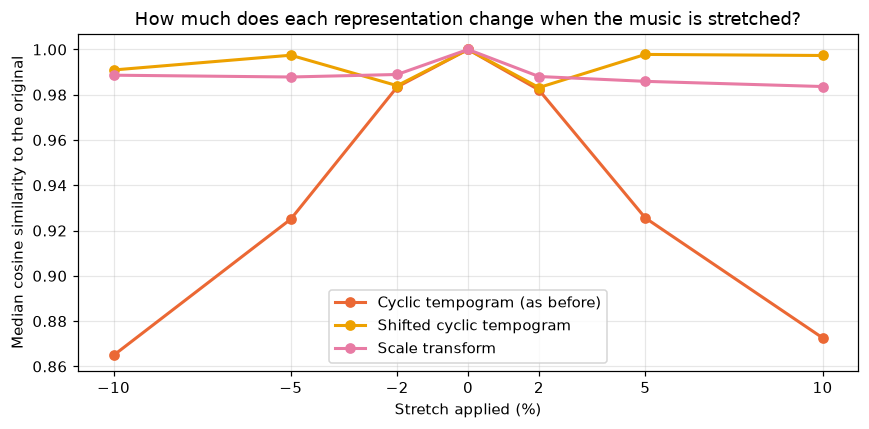

In [5]:
representations = {'Cyclic tempogram (as before)': F.CYCLIC_COLUMNS,
                   'Shifted cyclic tempogram': F.SHIFTED_COLUMNS,
                   'Scale transform': F.SCALE_COLUMNS}

original = versions[versions['condition'] == 'original'].set_index('filename')
rows = []
for condition, part in versions.groupby('condition'):
    part = part.set_index('filename').loc[original.index]
    for name, columns in representations.items():
        similarity = np.sum(part[columns].to_numpy()*original[columns].to_numpy(), axis=1)
        rows.append({'condition': condition, 'kind': part['kind'].iloc[0], 'rate': part['rate'].iloc[0],
                     'representation': name, 'median similarity': np.median(similarity),
                     'clips above 0.95 (%)': 100*np.mean(similarity > 0.95)})
similarity = pd.DataFrame(rows)
save(similarity, 'similarity_to_original.csv', index=False)

display(similarity[similarity['kind'] != 'original']
        .pivot_table(index='condition', columns='representation', values='median similarity')
        .loc[F.CONDITION_ORDER[1:]].round(3))

figure, axis = plt.subplots(figsize=(8, 4))
colors = ['#eb6834', '#eda100', '#e87ba4']
for (name, rows), color in zip(similarity.groupby('representation', sort=False), colors):
    rows = rows[rows['kind'].isin(['stretch', 'original'])].sort_values('rate')
    axis.plot(100*(rows['rate'] - 1), rows['median similarity'], marker='o', linewidth=2, color=color, label=name)
axis.set(xlabel='Stretch applied (%)', ylabel='Median cosine similarity to the original',
         title='How much does each representation change when the music is stretched?')
axis.set_xticks([-10, -5, -2, 0, 2, 5, 10])
axis.grid(alpha=0.3)
axis.legend()
figure.tight_layout()
save_figure(figure, 'similarity_to_original.png')

The cyclic tempogram as before changes a lot: at ±10% its median similarity drops to about 0.87. The shifted cyclic tempogram and the scale transform stay above 0.98 for every stretch, so on paper both are tempo-free.

Two details matter for the results below. First, the shifted tempogram changes a bit more at ±2% than at ±5% and ±10%. The reason is the bin size. One bin is about 4.7% of tempo, so a 5% or 10% stretch moves the profile by almost a whole number of bins (1.06 and 2.06), and the rotation removes that completely. A 2% stretch moves it by about half a bin, and that changes the shape of the profile. Second, the scale transform changes more after a round trip than after a stretch, so it reacts to the processing itself and not only to the tempo.

## 6. The feature sets

In [6]:
RHYTHM_COLUMNS = F.CYCLIC_COLUMNS + F.RATIO_COLUMNS + ['plp_confidence']
TEMPO_FREE_COLUMNS = F.SHIFTED_COLUMNS + F.RATIO_COLUMNS + ['plp_confidence']

FEATURE_SETS = {
    'Rhythm (as before)': RHYTHM_COLUMNS,
    'Tempo only': ['tau_hat'],
    'Rhythm, tempo removed': TEMPO_FREE_COLUMNS,
    'Scale transform': F.SCALE_COLUMNS,
    'Rhythm, tempo removed + tempo': TEMPO_FREE_COLUMNS + ['tau_hat'],
}
display(pd.Series({name: len(columns) for name, columns in FEATURE_SETS.items()}, name='inputs').to_frame())

,inputs
Rhythm (as before),19
Tempo only,1
"Rhythm, tempo removed",19
Scale transform,20
"Rhythm, tempo removed + tempo",20


## 7. Training

For every feature set and both classifiers we run the same nested cross-validation as the main notebooks: for each of the five test folds, a default model and a tuned model (grid search on three inner folds) are trained on the other four folds, using the original audio only. The grids are the ones from the rhythm notebooks. This cell takes a few minutes.

In [7]:
cv = {}
for model_name in MODEL_NAMES:
    for set_name, columns in FEATURE_SETS.items():
        print(f'{model_name}, {set_name} ({len(columns)} inputs)')
        cv[model_name, set_name] = E.run_nested_cv(data, columns, model_name, n_jobs=N_JOBS)

fold_metrics = pd.concat([result.fold_metrics.assign(model=model_name, feature_set=set_name)
                          for (model_name, set_name), result in cv.items()], ignore_index=True)
best_parameters = pd.concat([result.best_parameters.assign(model=model_name, feature_set=set_name)
                             for (model_name, set_name), result in cv.items()], ignore_index=True)
save(fold_metrics, 'fold_metrics.csv', index=False)
save(best_parameters, 'best_parameters.csv', index=False)

Random Forest, Rhythm (as before) (19 inputs)


    tuned macro-F1 per fold: 0.821, 0.760, 0.820, 0.839, 0.816


Random Forest, Tempo only (1 inputs)


    tuned macro-F1 per fold: 0.592, 0.556, 0.624, 0.608, 0.578


Random Forest, Rhythm, tempo removed (19 inputs)


...

    tuned macro-F1 per fold: 0.709, 0.673, 0.668, 0.637, 0.647


SVM-RBF, Scale transform (20 inputs)


    tuned macro-F1 per fold: 0.783, 0.706, 0.700, 0.673, 0.723


SVM-RBF, Rhythm, tempo removed + tempo (20 inputs)


    tuned macro-F1 per fold: 0.739, 0.722, 0.730, 0.665, 0.693


## 8. Results on the original audio

Mean ± SD over the five test folds, tuned models. The first two rows should be close to the main README (rhythm about 80-81%, tempo only about 59-60%); the next cell checks this against the saved main results.

In [8]:
tuned = fold_metrics[fold_metrics['variant'] == 'Tuned']
summary = E.summarize_folds(tuned, ['accuracy', 'macro_f1'], by=('feature_set', 'model'))
save(summary, 'metric_summary.csv', index=False)

table = pd.DataFrame({model_name: [f'{100*m:.1f} ± {100*s:.1f}' for m, s in
                                   zip(rows['macro_f1_mean'], rows['macro_f1_std'])]
                      for model_name, rows in summary.groupby('model', sort=False)},
                     index=summary['feature_set'].unique())
table.index.name = 'macro-F1 (%)'
display(table)

,Random Forest,SVM-RBF
macro-F1 (%),,
Rhythm (as before),81.1 ± 3.0,80.2 ± 3.5
Tempo only,59.1 ± 2.6,60.0 ± 3.8
"Rhythm, tempo removed",65.1 ± 5.5,66.7 ± 2.8
Scale transform,69.2 ± 5.0,71.7 ± 4.1
"Rhythm, tempo removed + tempo",78.4 ± 4.3,71.0 ± 3.1


In [9]:
# the two reference sets against the saved results of the main notebooks
main_dirs = {('Random Forest', 'Rhythm (as before)'): 'rhythm_random_forest/rhythm',
             ('Random Forest', 'Tempo only'): 'rhythm_random_forest/tempo_only',
             ('SVM-RBF', 'Rhythm (as before)'): 'rhythm_svm_rbf/rhythm',
             ('SVM-RBF', 'Tempo only'): 'rhythm_svm_rbf/tempo_only'}
rows = []
for (model_name, set_name), folder in main_dirs.items():
    path = MAIN_RESULTS_DIR / folder / 'metric_summary.csv'
    if path.is_file():
        before = pd.read_csv(path).set_index('variant').loc['Tuned', 'macro_f1_mean']
        now = summary.set_index(['feature_set', 'model']).loc[(set_name, model_name), 'macro_f1_mean']
        rows.append({'model': model_name, 'feature set': set_name, 'main notebooks (%)': 100*before,
                     'here (%)': 100*now, 'difference (pp)': 100*(now - before)})
display(pd.DataFrame(rows).round(2) if rows else 'main results not found, check skipped')

,model,feature set,main notebooks (%),here (%),difference (pp)
0,Random Forest,Rhythm (as before),80.75,81.12,0.37
1,Random Forest,Tempo only,59.15,59.15,0.00
2,SVM-RBF,Rhythm (as before),80.25,80.25,0.00
3,SVM-RBF,Tempo only,60.05,60.05,0.00


The two reference sets give the same numbers as the main notebooks (exactly the same for three of the four, and 0.4 points higher for the rhythm Random Forest).

Removing the tempo costs something, but much less than the main experiment suggested. Without the tempo, the rhythm set gets 65-67% instead of about 80%, and the scale transform gets 69-72%. That is above the tempo-only baseline (about 60%) and far above chance (12.5%), so the rhythm pattern alone does carry information about the dance. Earlier work found about 50% for tempo-free rhythm patterns on Ballroom (Dixon et al., 2004), so our numbers are in the same range or a bit higher.

When we give the tempo back (last row), the Random Forest goes up to 78%, close to the original rhythm set. The SVM only reaches 71%.

## 9. Results on the stretched audio

The fold models from the training section are used as they are; only `.predict()` is called on the features of the changed audio. For every model and feature set:

- the macro-F1 on the original audio and at −10% and +10%,
- the mean change over the six stretches and over the six round trips,
- "caused by tempo": the stretch change minus the round-trip change, the same measure as in the main README,
- the flip rate: the share of clips whose prediction changes when the audio is stretched.

The figure shows the tuned models. Left: stretched audio; right: round trip.

In [10]:
condition_metrics, held_out = {}, []
for (model_name, set_name), result in cv.items():
    metrics, predictions = E.evaluate_conditions(result, data, versions, F.CONDITIONS)
    condition_metrics[model_name, set_name] = metrics.assign(model=model_name, feature_set=set_name)
    held_out.append(predictions.assign(model=model_name, feature_set=set_name))

all_condition_metrics = pd.concat(condition_metrics.values(), ignore_index=True)
save(all_condition_metrics, 'stretch_fold_metrics.csv', index=False)
save(pd.concat(held_out, ignore_index=True), 'held_out_predictions_tuned.csv', index=False)

robustness = E.summarize_folds(all_condition_metrics, ['accuracy', 'macro_f1', 'flip_rate', 'macro_f1_change_pp'],
                               by=('model', 'feature_set', 'variant', 'condition', 'kind', 'rate', 'tempo_change_percent'))
save(robustness, 'robustness_summary.csv', index=False)

tempo_effect = pd.DataFrame([{'model': model_name, 'feature set': set_name, **E.tempo_effect_row(metrics)}
                             for (model_name, set_name), metrics in condition_metrics.items()])
tempo_effect = tempo_effect.set_index(['model', 'feature set'])
save(tempo_effect, 'tempo_effect.csv')
display(tempo_effect.round(1))

original macro-F1 (%)  \
model         feature set                                            
Random Forest Rhythm (as before)                              81.1   
              Tempo only                                      59.1   
              Rhythm, tempo removed                           65.1   
              Scale transform                                 69.2   
              Rhythm, tempo removed + tempo                   78.4   
SVM-RBF       Rhythm (as before)                              80.2   
              Tempo only                                      60.0   
              Rhythm, tempo removed                           66.7   
              Scale transform                                 71.7   
              Rhythm, tempo removed + tempo                   71.0   

                                             at -10% (%)  at +10% (%)  \
model         feature set                                               
Random Forest Rhythm (as before)                    27.5         16.0   
              Tempo only                            13.4          8.9   
              Rhythm, tempo removed                 39.1         56.5   
              Scale transform                       51.1         46.0   
              Rhythm, tempo removed + tempo         36.4         29.7   
SVM-RBF       Rhythm (as before)                    29.5         17.6   
              Tempo only                            10.0          9.2   
              Rhythm, tempo removed                 38.6         53.4   
              Scale transform                       54.0         46.8   
              Rhythm, tempo removed + tempo         38.9         54.4   

                                             mean change, stretch (pp)  \
model         feature set                                                
Random Forest Rhythm (as before)                                 -37.5   
              Tempo only                                         -34.9   
              Rhythm, tempo removed                              -14.2   
              Scale transform                                    -22.1   
              Rhythm, tempo removed + tempo                      -28.0   
SVM-RBF       Rhythm (as before)                                 -36.8   
              Tempo only                                         -37.7   
              Rhythm, tempo removed                              -16.4   
              Scale transform                                    -20.2   
              Rhythm, tempo removed + tempo                      -16.0   

                                             mean change, round trip (pp)  \
model         feature set                                                   
Random Forest Rhythm (as before)                                     -6.1   
              Tempo only                                              0.1   
              Rhythm, tempo removed                                  -4.8   
              Scale transform                                       -31.6   
              Rhythm, tempo removed + tempo                          -7.0   
SVM-RBF       Rhythm (as before)                                     -5.4   
              Tempo only                                              0.7   
              Rhythm, tempo removed                                  -5.5   
              Scale transform                                       -29.2   
              Rhythm, tempo removed + tempo                          -2.7   

                                             caused by tempo (pp)  \
model         feature set                                           
Random Forest Rhythm (as before)                            -31.4   
              Tempo only                                    -35.0   
              Rhythm, tempo removed                          -9.3   
              Scale transform                                 9.5   
              Rhythm, tempo removed + tempo                 -21.0   
SVM-RBF       Rhythm (as befor

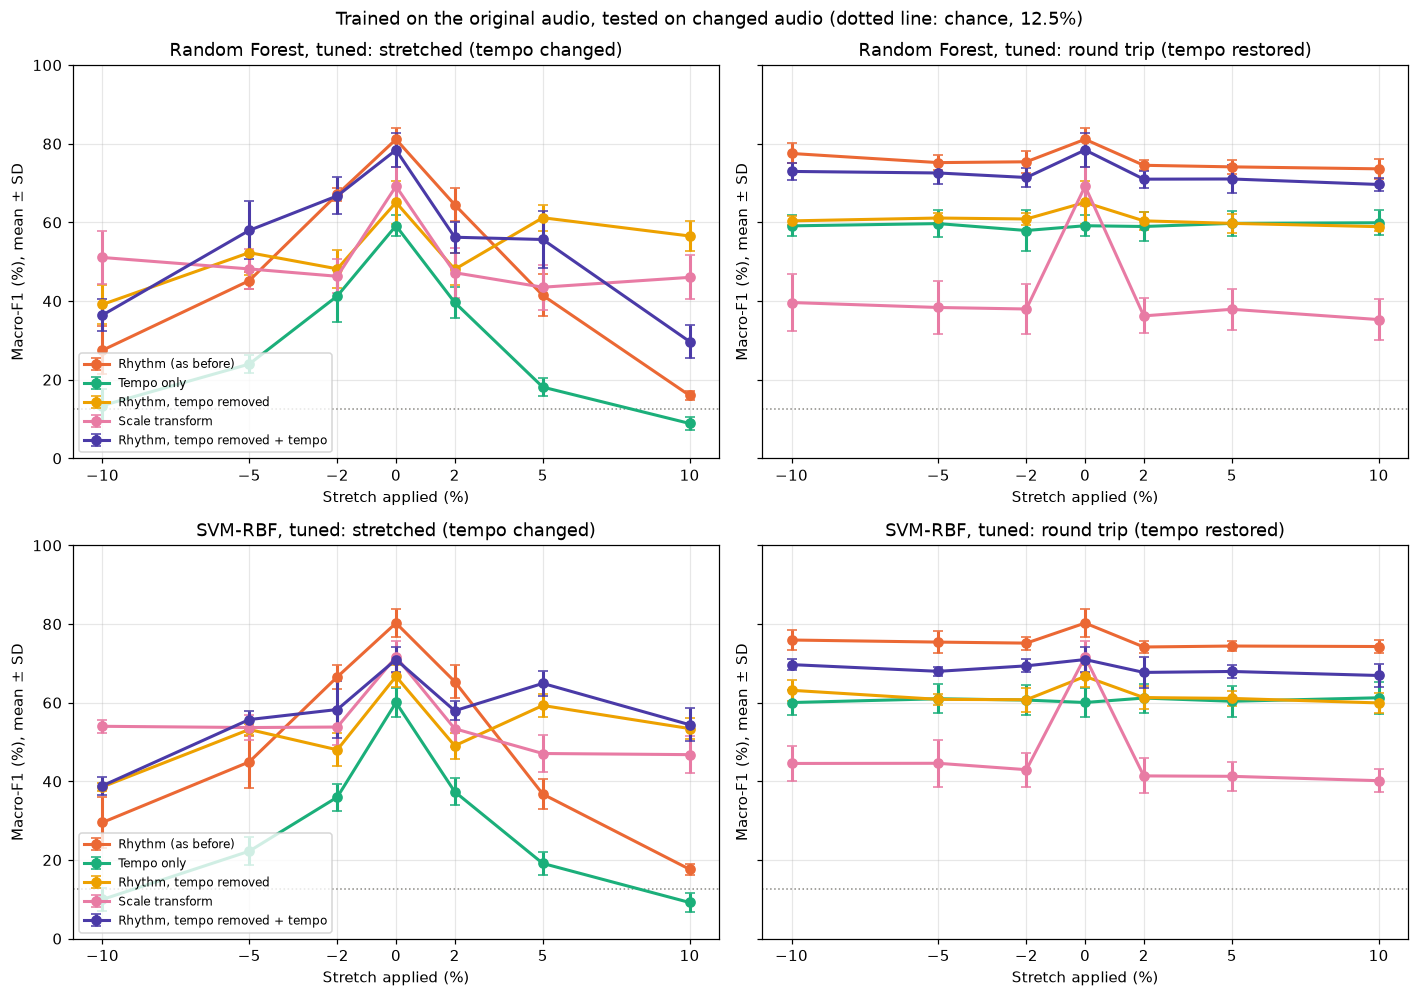

In [11]:
figure, axes = plt.subplots(len(MODEL_NAMES), 2, figsize=(13, 4.6*len(MODEL_NAMES)), sharey=True)
for row, model_name in enumerate(MODEL_NAMES):
    curves = {set_name: condition_metrics[model_name, set_name] for set_name in FEATURE_SETS}
    E.plot_robustness(curves, {name: E.SET_COLORS[name] for name in FEATURE_SETS}, model_name, axes[row])
figure.suptitle('Trained on the original audio, tested on changed audio (dotted line: chance, 12.5%)')
figure.tight_layout()
save_figure(figure, 'robustness_curves.png')

Rhythm, tempo removed: the part of the drop that comes from the tempo goes from about −31 points to about −9 to −11 points. At +5% and +10% the models still get 53-61%, while the original rhythm set falls to 16-41%.

The drop that is left is mostly not a tempo shortcut. It follows the bin size problem from section 5. If we only look at the clips whose tempo estimate follows the stretch correctly, the Random Forest gets 62% at +5% and 58% at +10% (shift close to a whole number of bins), but about 49-50% at ±2% (half a bin). At −10% it is lowest (45%); this is also the stretch where the tempo estimate jumps most often (for 25% of the clips), and clips with a jump change their prediction more often (72% against 49%). The bar ratios are measured at the estimated beat, so a jump changes them too.

Scale transform: the curve under stretching is flat (46-54%), and the round trip is even worse than the stretch, so the tempo itself does not matter for this model ("caused by tempo" is positive). But it loses 20-30 points as soon as the audio goes through the phase vocoder at all. So the scale transform is tempo-invariant but very sensitive to the stretching artifacts. A likely reason is that on a log lag axis the short lags (0.1-0.4 s) take up a large part of the axis, and that is exactly where the smeared drum attacks change the autocorrelation. We did not tune it further, because we would then be choosing settings from test results.

Rhythm, tempo removed + tempo: with the tempo back, the Random Forest becomes fragile again (−21 points caused by tempo). The SVM is in between (−13 points).

## 10. Which dances can be recognised without the tempo?

F1 per dance on the original audio (tuned Random Forest), for the rhythm set as before, the tempo-only set and the two tempo-free sets.

In [12]:
per_genre = {}
for set_name in ['Rhythm (as before)', 'Tempo only', 'Rhythm, tempo removed', 'Scale transform']:
    predictions = cv['Random Forest', set_name].predictions
    per_genre[set_name] = pd.Series(f1_score(predictions['label'], predictions['prediction_tuned'],
                                            labels=class_labels, average=None), index=class_labels)
per_genre = 100*pd.DataFrame(per_genre)
save(per_genre, 'per_genre_f1_random_forest.csv')
display(per_genre.round(1))

,Rhythm (as before),Tempo only,"Rhythm, tempo removed",Scale transform
ChaChaCha,87.7,70.7,74.5,82.9
Jive,67.3,49.6,47.8,65.0
Quickstep,83.2,62.9,53.0,71.6
Rumba,76.5,55.5,58.9,60.2
Samba,82.0,35.6,68.5,87.6
Tango,85.2,68.6,69.3,71.4
VienneseWaltz,85.5,68.8,82.1,54.8
Waltz,81.0,61.1,66.7,61.9


The two tempo-free features are good at different dances. With the shifted tempogram, VienneseWaltz stays high (82%), but Jive (48%) and Quickstep (53%) drop a lot: these were the dances that the tempo identified well. The scale transform is strongest on Samba (88%) and ChaChaCha (83%) but weak on VienneseWaltz (55%). So the two features seem to capture different parts of the rhythm.

## 11. What does the model use when it gets the tempo back?

Group permutation importance for "Rhythm, tempo removed + tempo" (tuned models): we shuffle one family of inputs across the test clips and measure how much macro-F1 drops. A big drop means the model relies on that family.

In [13]:
groups = {'Shifted cyclic tempogram': F.SHIFTED_COLUMNS, 'Bar ratios': F.RATIO_COLUMNS,
          'PLP confidence': ['plp_confidence'], 'Tempo (tau_hat)': ['tau_hat']}
importance = pd.concat({model_name: 100*E.group_importance(cv[model_name, 'Rhythm, tempo removed + tempo'], data, groups)
                        for model_name in MODEL_NAMES}, axis=1)
importance.columns = [f'{model} {stat} (pp)' for model, stat in importance.columns]
save(importance, 'importance_tempo_free_plus_tempo.csv')
display(importance.round(1))

,Random Forest mean (pp),Random Forest std (pp),SVM-RBF mean (pp),SVM-RBF std (pp)
feature_family,,,,
Tempo (tau_hat),43.1,2.7,16.1,3.6
Shifted cyclic tempogram,37.3,6.9,46.7,3.1
Bar ratios,4.4,1.8,7.5,2.6
PLP confidence,1.7,1.1,2.9,2.5


The Random Forest relies on `tau_hat` as much as on the shifted tempogram (43 and 37 points), so as soon as the tempo is available, it uses it again. The SVM leans much more on the shifted tempogram (47 points) than on the tempo (16 points), which fits its smaller drop under stretching. The bar ratios and the PLP confidence matter little in both models, as in the main experiment.

## 12. Summary

- The rhythm pattern alone recognises the dances clearly above chance and above the tempo-only baseline: 65-67% with the shifted cyclic tempogram and 69-72% with the scale transform, against about 80% with the tempo included.
- Without the tempo, the models are much more robust to tempo changes. For the shifted tempogram, the part of the drop caused by the tempo goes from about 31 to about 10 points, and most of what is left comes from the 15-bin resolution and from jumps in the tempo estimate, not from a tempo shortcut.
- The scale transform does not react to the tempo at all, but it reacts strongly to the time-stretching artifacts. So "invariant on paper" is not the same as "robust in practice".
- When the tempo is added back, the Random Forest uses it again and becomes fragile again.

Possible next steps (not done here): a cyclic tempogram with more bins per octave, which should remove the dip at ±2%; and a scale transform that leaves out the shortest lags, or is also trained on processed audio.